# Simple and multiple regression: energy, market and oil

Analyse monthly US energy-sector returns for **2011–2025**. Start with a market-only
regression, then add changes in the Brent oil price. Interpret the coefficients and
their uncertainty, and compare the two specifications using the same observations.

The main goal is to read and explain regression results. State your expectations
before estimation and relate the output to economic reasoning.

## Environment setup

**Colab:** upload the complete `Notebooks` folder to **My Drive**, keeping the
subfolders and CSV files. Run the cell below and authorise Drive access.
**Local Jupyter:** keep the same folder structure and run the cell below.
If the folder is elsewhere, set `NOTEBOOKS_ROOT` to its full path.

In [1]:
from pathlib import Path

# Usually leave this as None. If needed, enter the path to the folder
# containing all tutorial subfolders (Google Drive or the Colab runtime).
NOTEBOOKS_ROOT = None
TUTORIAL = "OLS"

try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    notebooks_root = Path(NOTEBOOKS_ROOT or "/content/drive/MyDrive/Notebooks")
    if notebooks_root.is_relative_to("/content/drive"):
        drive.mount("/content/drive")
else:
    if NOTEBOOKS_ROOT is not None:
        notebooks_root = Path(NOTEBOOKS_ROOT).expanduser().resolve()
    else:
        # Work from the tutorial folder, Notebooks, or the course folder.
        here = Path.cwd().resolve()
        candidates = [here, *here.parents]
        candidates += [parent / "Notebooks" for parent in [here, *here.parents]]
        notebooks_root = next(
            (root for root in candidates if (root / TUTORIAL).is_dir()), here
        )

DATA_DIR = notebooks_root / TUTORIAL
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Tutorial folder not found: {DATA_DIR}. "
        "Upload the complete Notebooks folder to My Drive, or set "
        "NOTEBOOKS_ROOT to the folder containing the tutorial subfolders."
    )
print(f"Data folder found: {DATA_DIR.name}")

Data folder found: OLS


## Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display

## Data and units

- **Energy:** total returns on the value-weighted US energy portfolio in the
  [Kenneth French 12 industry portfolios](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/det_12_ind_port.html).
- **Market and RF:** monthly market excess returns and risk-free returns from the
  [Kenneth French factor data](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/f-f_factors.html).
- **Brent:** the last available [EIA/FRED spot price](https://fred.stlouisfed.org/series/DCOILBRENTEU)
  in each month. Its percentage change is an explanatory variable, not a futures return.

Equity returns and RF are supplied as decimals. We subtract the matched monthly RF
from the energy total return. The market series is already an excess return.

All regression variables below are in **percent**: a value of 1 means a 1% return.
A one-unit increase is therefore **one percentage point**, not a 1% increase relative
to the variable's previous value. RF is a monthly return, not an annualised yield.

December 2010 provides the base price for the first Brent change. It is excluded
from estimation. Month-end labels identify the month; the CSV also records the
date of the Brent price actually used.

In [3]:
data = pd.read_csv(DATA_DIR / "monthly_energy_market_data.csv", parse_dates=["date"])
data = data.set_index("date").sort_index()

returns = pd.DataFrame({
    "Energy": 100 * (data["Energy"] - data["RF"]),
    "Market": 100 * data["Market_excess"],
    "Brent": 100 * data["Brent_spot"].pct_change(fill_method=None),
}).loc["2011-01-01":"2025-12-31"]

if returns.isna().any().any():
    raise ValueError("Missing observations: check the data before comparing the models.")
print(f"Estimation sample: {returns.index[0]:%Y-%m} to {returns.index[-1]:%Y-%m}; {len(returns)} months")
display(returns.head().round(3))

Estimation sample: 2011-01 to 2025-12; 180 months


,Energy,Market,Brent
date,,,
2011-01-31,6.92,1.98,6.157
2011-02-28,7.62,3.48,13.438
2011-03-31,2.10,0.45,4.160
2011-04-30,1.58,2.90,8.252
2011-05-31,-4.51,-1.27,-7.433


## Before estimation: expectations

What sign do you expect for the market coefficient? What additional information
might oil-price changes contain for energy stocks? Discuss why market and oil-price
movements might be related, and whether every monthly energy return should move
in the same direction as either variable.

## 1. Simple regression: the market model

Estimate the CAPM-style excess-return regression

$$r^e_{E,t}=\alpha+\beta_M r^e_{M,t}+u_t.$$

The intercept is the fitted energy excess return when the market excess return is
zero. The slope measures the fitted change in energy excess return associated with
a one-percentage-point increase in market excess return.

The intercept is often called **alpha**, and the market slope **beta**. They are
estimated coefficients: their economic interpretation and their precision are
separate questions.

In [4]:
y = returns["Energy"]
X_simple = sm.add_constant(returns[["Market"]])
simple = sm.OLS(y, X_simple, missing="raise").fit()
print(simple.summary())

                            OLS Regression Results                            
Dep. Variable:                 Energy   R-squared:                       0.401
Model:                            OLS   Adj. R-squared:                  0.398
Method:                 Least Squares   F-statistic:                     119.2
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           1.45e-21
Time:                        03:13:29   Log-Likelihood:                -577.72
No. Observations:                 180   AIC:                             1159.
Df Residuals:                     178   BIC:                             1166.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.6295      0.463     -1.359      0.1

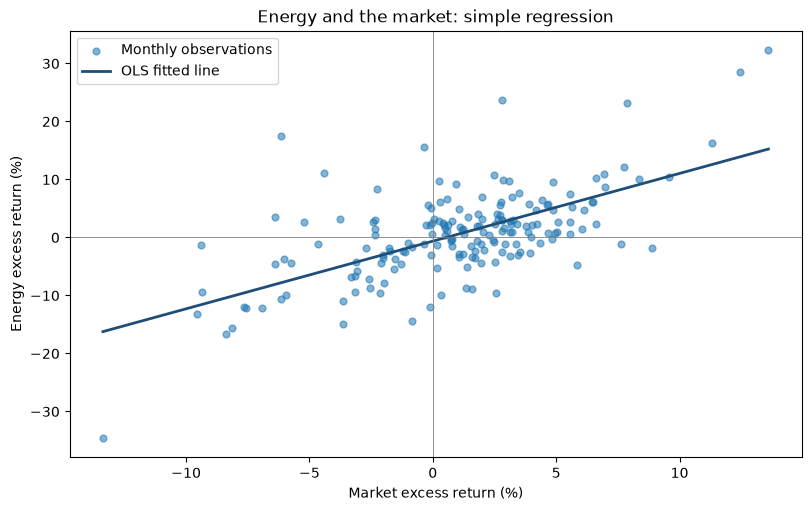

In [5]:
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.scatter(returns["Market"], y, s=24, alpha=0.55, label="Monthly observations")
market_grid = np.linspace(returns["Market"].min(), returns["Market"].max(), 100)
ax.plot(market_grid, simple.params["const"] + simple.params["Market"] * market_grid,
        color="#1F4E79", lw=2, label="OLS fitted line")
ax.axhline(0, color="grey", lw=0.6)
ax.axvline(0, color="grey", lw=0.6)
ax.set(xlabel="Market excess return (%)", ylabel="Energy excess return (%)",
       title="Energy and the market: simple regression")
ax.legend()
plt.show()

## Reading the regression output

| Output | Interpretation |
|---|---|
| `coef` | Estimated intercept or slope; interpret its sign, size and units. |
| `std err` | Estimated sampling uncertainty of the coefficient. It is not the volatility of returns or the standard deviation of the residuals. |
| `t` | For the displayed zero-coefficient test, the estimate divided by its standard error. |
| `P>|t|` | Two-sided p-value for $H_0:\theta=0$ against $H_1:\theta\ne0$, separately for each coefficient. |
| `[0.025, 0.975]` | Endpoints of the 95% confidence interval for the coefficient. |
| `R-squared` | Fraction of the sample variation in the dependent variable explained by the fitted regression with an intercept. |

Under $H_0$ and the test assumptions, the **p-value** is the probability of a test
statistic at least as extreme as the observed one, in either direction. It is not
the probability that $H_0$ is true, and does not measure the economic size of an effect.
A displayed `0.000` is rounding, not an exactly zero probability.

At 5%, reject the zero-coefficient null when the p-value is below 0.05. Non-rejection
does not establish that the coefficient is zero. A **Type I error** is rejecting a
true null; the significance level concerns repeated use of the test under that null.

A 95% confidence-interval procedure covers the true coefficient in 95% of repeated
samples under its assumptions. Inclusion of zero corresponds to non-rejection by
the matching two-sided 5% test. Compare the width of the interval with the coefficient's size.

These are **conventional OLS standard errors and tests**. Their validity depends
on the error assumptions; the exact Student reference additionally requires
conditional Normality. Heteroskedasticity and alternative standard errors will be
examined separately.

**Discuss:** interpret alpha and market beta in a sentence each. Which null does
the reported beta p-value test? Does significance imply beta differs from one?
What do the scatter and $R^2$ say about the returns that the market does not explain?

## 2. Multiple regression: adding Brent

$$r^e_{E,t}=\alpha+\beta_M r^e_{M,t}+\beta_O\Delta p^{Brent}_t+u_t.$$

$\Delta p^{Brent}_t$ is the monthly percentage change in the spot price.
The market coefficient now describes the association **holding Brent changes
constant**; the Brent coefficient holds market excess return constant.
The intercept corresponds to both explanatory variables being zero.

Before viewing the output, state your expectation for $\beta_O$ and explain whether
you expect the estimated market beta to remain unchanged.

In [6]:
X_multiple = sm.add_constant(returns[["Market", "Brent"]])
multiple = sm.OLS(y, X_multiple, missing="raise").fit()
print(multiple.summary())

                            OLS Regression Results                            
Dep. Variable:                 Energy   R-squared:                       0.531
Model:                            OLS   Adj. R-squared:                  0.525
Method:                 Least Squares   F-statistic:                     100.0
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           8.54e-30
Time:                        03:13:29   Log-Likelihood:                -555.78
No. Observations:                 180   AIC:                             1118.
Df Residuals:                     177   BIC:                             1127.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.4757      0.412     -1.155      0.2

**Discuss:** interpret the Brent coefficient for a one-percentage-point change
and for a ten-percentage-point change. State its null and alternative hypotheses;
interpret its standard error, p-value and confidence interval.
Does an economically plausible sign establish a causal effect?

## 3. Comparing the models

Both models use the same months and dependent variable. Compare the coefficients
and their precision, then compare fit. The residual standard deviation below is
in percentage points and measures unexplained return variation.

In [7]:
models = {"Market only": simple, "Market + Brent": multiple}
comparison = pd.DataFrame({
    name: {"Observations": int(model.nobs),
           "Alpha (% per month)": model.params["const"],
           "Market beta": model.params["Market"],
           "SE: market beta": model.bse["Market"],
           "R-squared": model.rsquared,
           "Adjusted R-squared": model.rsquared_adj,
           "Residual SD (pp)": np.sqrt(model.mse_resid)}
    for name, model in models.items()
})
display(comparison.round(4))
print(f"Market–Brent sample correlation: {returns['Market'].corr(returns['Brent']):.3f}")

,Market only,Market + Brent
Observations,180.0000,180.0000
Alpha (% per month),-0.6295,-0.4757
Market beta,1.1672,0.8825
SE: market beta,0.1069,0.1033
R-squared,0.4010,0.5306
Adjusted R-squared,0.3977,0.5253
Residual SD (pp),6.0268,5.3503


Market–Brent sample correlation: 0.394


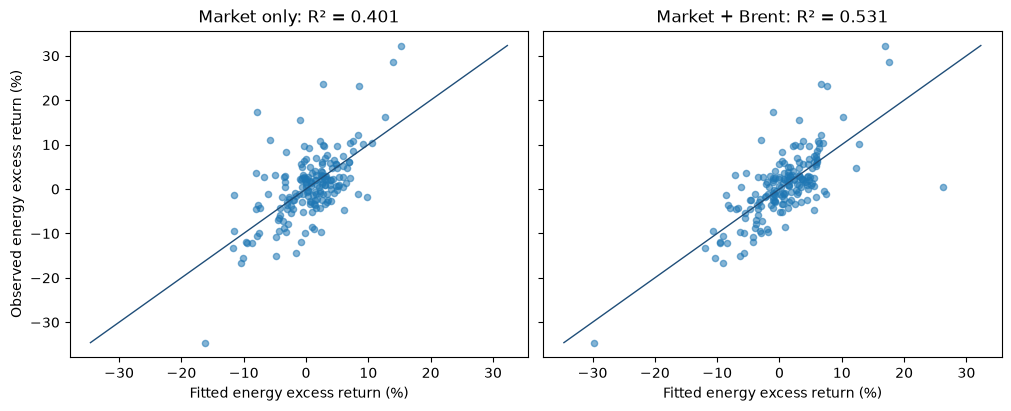

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True,
                         constrained_layout=True)
limits = [min(y.min(), *(m.fittedvalues.min() for m in models.values())),
          max(y.max(), *(m.fittedvalues.max() for m in models.values()))]
for ax, (name, model) in zip(axes, models.items()):
    ax.scatter(model.fittedvalues, y, s=20, alpha=0.55)
    ax.plot(limits, limits, color="#1F4E79", lw=1)
    ax.set(title=f"{name}: R² = {model.rsquared:.3f}",
           xlabel="Fitted energy excess return (%)")
axes[0].set_ylabel("Observed energy excess return (%)")
plt.show()

**Discuss:** how do alpha, market beta, its standard error and the unexplained
variation change? How much additional variation does Brent explain?

Adding a regressor cannot lower ordinary in-sample $R^2$ on the same sample.
Adjusted $R^2$ penalises additional regressors and need not increase. Neither
statistic establishes causality or guarantees good forecasts.

The difference in market beta provides a link to **omitted variable bias**:
consider Brent's association with energy returns and its correlation with the
market. A changed coefficient alone does not establish that either model has
identified a causal parameter. Multiple-regression coefficients describe partial
associations unless further identifying assumptions are justified.

## To do

Using the estimated multiple-regression coefficients, calculate the fitted energy
excess return when market excess return is **1%** and the Brent price change is
**10%**. Compare it with the fitted value when both regressors are zero.
Explain the contribution of each coefficient and why the fitted value is not
a guaranteed realised return.

## Relevant concepts

- Simple and multiple regression; intercept and slope coefficients; units.
- Partial associations and interpretation holding other regressors constant.
- Standard errors; t-tests; p-values; confidence intervals; Type I error.
- Statistical versus economic significance.
- Fitted values and residuals; $R^2$ and adjusted $R^2$; omitted variable bias.